# Crop price index at the grid-cell level

> To write (Andrew): what this notebook does and why. Points to cover: we follow Berman et al. (2023),
> equations (1) and (2); each 5 arc-minute cell (about 9 km) gets its own price index, a weighted
> average of world crop prices where the weights are the relative agronomic suitability of the cell
> for each crop; suitability depends only on climate, soil and terrain, so it is not chosen by farmers.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import rasterio

plt.style.use("default")
plt.rcParams["figure.facecolor"] = "white"

# Data is read from GitHub so the notebook runs on any computer.
# Switch BRANCH to "main" once the branch is merged.
BRANCH = "andrew-cleanup-berman"
BASE = f"https://raw.githubusercontent.com/AndrewEberhardt/DataScienceProject/{BRANCH}/data/"
GAEZ_URL = BASE + "raw/gaez/sxHr_{}.tif"

# Crop -> (GAEZ v4 codes, World Bank Pink Sheet series). Rice: max of dryland and wetland rice.
# Coffee: average of the Arabica and Robusta prices.
CROPS = {
    "banana":    (["ban"], ["Banana, US"]),
    "cocoa":     (["coc"], ["Cocoa"]),
    "coconut":   (["con"], ["Coconut oil"]),
    "coffee":    (["cof"], ["Coffee, Arabica", "Coffee, Robusta"]),
    "cotton":    (["cot"], ["Cotton, A Index"]),
    "maize":     (["mze"], ["Maize"]),
    "oil palm":  (["olp"], ["Palm oil"]),
    "rice":      (["rcd", "rcw"], ["Rice, Thai 5%"]),
    "soybean":   (["soy"], ["Soybeans"]),
    "sugarcane": (["suc"], ["Sugar, world"]),
    "tea":       (["tea"], ["Tea, avg 3 auctions"]),
    "tobacco":   (["tob"], ["Tobacco, US import u.v."]),
    "wheat":     (["whe"], ["Wheat, US HRW"]),
    "barley":    (["brl"], ["Barley"]),
    "sorghum":   (["srg"], ["Sorghum"]),
}
CROPS_13 = list(CROPS)[:13]          # main index, 2001-2025
CROPS_15 = list(CROPS)               # Berman et al. crops, replication 2001-2018
YEARS_13 = list(range(2001, 2026))
YEARS_15 = list(range(2001, 2019))
SOURCE_GAEZ = "Source: FAO/IIASA GAEZ v4 (high input, rainfed, 1961-1990), Hansen et al. GFC v1.13."
SOURCE_PRICE = "Source: World Bank Commodity Price Data (Pink Sheet), real prices."

## 2. Grid cells

One row per GAEZ 5 arc-minute cell of the 62 sample countries with tree cover above 25 percent in 2000
(built from the Hansen pixels by `scripts/build_grid_panel.py` and `scripts/assemble_grid_panel.py`).

In [2]:
cells = pd.read_csv(BASE + "processed/grid_cells.csv.gz",
                    usecols=["cell_id", "row", "col", "lat", "lon", "iso3", "in_tropics",
                             "pixel_area_ha", "forest25_px"])
regions = pd.read_csv(BASE + "processed/shock_panel.csv")[["iso3", "country", "region"]].drop_duplicates()
cells = cells.merge(regions, on="iso3", how="left")
cells["forest25_ha"] = cells.forest25_px * cells.pixel_area_ha
print(f"cells: {len(cells):,} | countries: {cells.iso3.nunique()} | in tropics band: {cells.in_tropics.sum():,}")
cells.groupby("region").agg(cells=("cell_id", "size"), forest_2000_Mha=("forest25_ha", lambda x: x.sum() / 1e6)).round(1)

cells: 511,427 | countries: 62 | in tropics band: 406,547


,cells,forest_2000_Mha
region,,
Africa,143891,648.4
Asia-Pacific,145745,475.6
Latin America & Caribbean,221791,1025.1


## 3. Crop suitability

GAEZ suitability index (0 to 10,000) of each crop in each cell, rescaled to 0-1.
Water and missing cells (value -9) count as not suitable.

In [3]:
suit = pd.DataFrame({"cell_id": cells.cell_id})
for crop, (codes, _) in CROPS.items():
    layers = []
    for c in codes:
        with rasterio.open(GAEZ_URL.format(c)) as src:
            assert src.shape == (2160, 4320) and src.transform.c == -180 and src.transform.f == 90
            a = src.read(1).astype(np.float32)
        layers.append(np.clip(a, 0, None)[cells.row.values, cells.col.values] / 10000)
    suit[crop] = np.max(layers, axis=0)

desc = suit[CROPS_15].describe().T[["mean", "50%", "max"]]
desc["share_cells_suitable"] = (suit[CROPS_15] >= 0.4).mean()   # GAEZ class medium or better
desc.round(3).sort_values("mean", ascending=False)

,mean,50%,max,share_cells_suitable
rice,0.420,0.467,1.000,0.561
soybean,0.405,0.414,1.000,0.515
maize,0.357,0.320,1.000,0.362
cotton,0.301,0.243,1.000,0.335
sorghum,0.300,0.238,1.000,0.335
tobacco,0.297,0.283,1.000,0.322
sugarcane,0.289,0.273,1.000,0.350
coffee,0.279,0.229,1.000,0.363
cocoa,0.258,0.090,1.000,0.340
banana,0.257,0.167,1.000,0.313


Cells with zero suitability for every crop have no price index (Berman et al. keep only cells with
suitability data). How much forest do we lose?

In [4]:
for name, crops in [("13 crops", CROPS_13), ("15 crops", CROPS_15)]:
    none = suit[crops].sum(axis=1) == 0
    print(f"{name}: cells with no suitable crop {none.sum():,} ({none.mean():.1%}), "
          f"share of forest 2000 {cells.forest25_ha[none].sum() / cells.forest25_ha.sum():.1%}")
    print("   by region:", cells[none].region.value_counts().to_dict())

13 crops: cells with no suitable crop 24,091 (4.7%), share of forest 2000 0.5%
   by region: {'Latin America & Caribbean': 12561, 'Asia-Pacific': 9814, 'Africa': 1716}
15 crops: cells with no suitable crop 22,766 (4.5%), share of forest 2000 0.5%
   by region: {'Latin America & Caribbean': 12174, 'Asia-Pacific': 8923, 'Africa': 1669}


Share of the variance of suitability that is **within** countries (Berman et al., Table OA.1).
Country x year fixed effects remove everything national, so the index must vary inside countries.

In [5]:
within = {}
for crop in CROPS_15:
    total = suit[crop].var()
    between = suit[crop].groupby(cells.iso3).transform("mean").var()
    within[crop] = 1 - between / total
pd.Series(within, name="share_within_country").sort_values().round(2).to_frame().T

,coffee,cocoa,sorghum,banana,rice,oil palm,wheat,sugarcane,cotton,barley,coconut,tobacco,tea,maize,soybean
share_within_country,0.54,0.56,0.59,0.61,0.62,0.62,0.63,0.63,0.66,0.66,0.67,0.7,0.73,0.73,0.74


## 4. World crop prices (base 100 in 2000)

In [6]:
prices = pd.read_csv(BASE + "processed/commodity_prices_annual.csv")
P = {}
for crop, (_, series) in CROPS.items():
    s = (prices[prices.commodity.isin(series)]
         .groupby("year").price_real.mean())          # average when two series (coffee)
    P[crop] = 100 * s / s.loc[2000]
P = pd.DataFrame(P).loc[2000:2025]
print("last year with a price:", P.apply(lambda s: s.last_valid_index()).to_dict())
P.loc[[2000, 2008, 2011, 2018, 2022, 2025], CROPS_15].round(0)

last year with a price: {'banana': 2025, 'cocoa': 2025, 'coconut': 2025, 'coffee': 2025, 'cotton': 2025, 'maize': 2025, 'oil palm': 2025, 'rice': 2025, 'soybean': 2025, 'sugarcane': 2025, 'tea': 2025, 'tobacco': 2025, 'wheat': 2025, 'barley': 2020, 'sorghum': 2020}


,banana,cocoa,coconut,coffee,cotton,maize,oil palm,rice,soybean,sugarcane,tea,tobacco,wheat,barley,sorghum
year,,,,,,,,,,,,,,,
2000,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2008,155.0,220.0,210.0,148.0,93.0,195.0,260.0,249.0,191.0,117.0,100.0,93.0,221.0,201.0,183.0
2011,164.0,235.0,275.0,212.0,183.0,236.0,276.0,192.0,182.0,226.0,111.0,108.0,199.0,192.0,219.0
2018,213.0,197.0,173.0,132.0,121.0,145.0,161.0,162.0,145.0,117.0,119.0,128.0,144.0,127.0,150.0
2022,240.0,179.0,246.0,189.0,149.0,244.0,278.0,146.0,216.0,152.0,110.0,97.0,255.0,NaN,NaN
2025,177.0,589.0,377.0,322.0,90.0,157.0,222.0,138.0,134.0,139.0,106.0,158.0,146.0,NaN,NaN


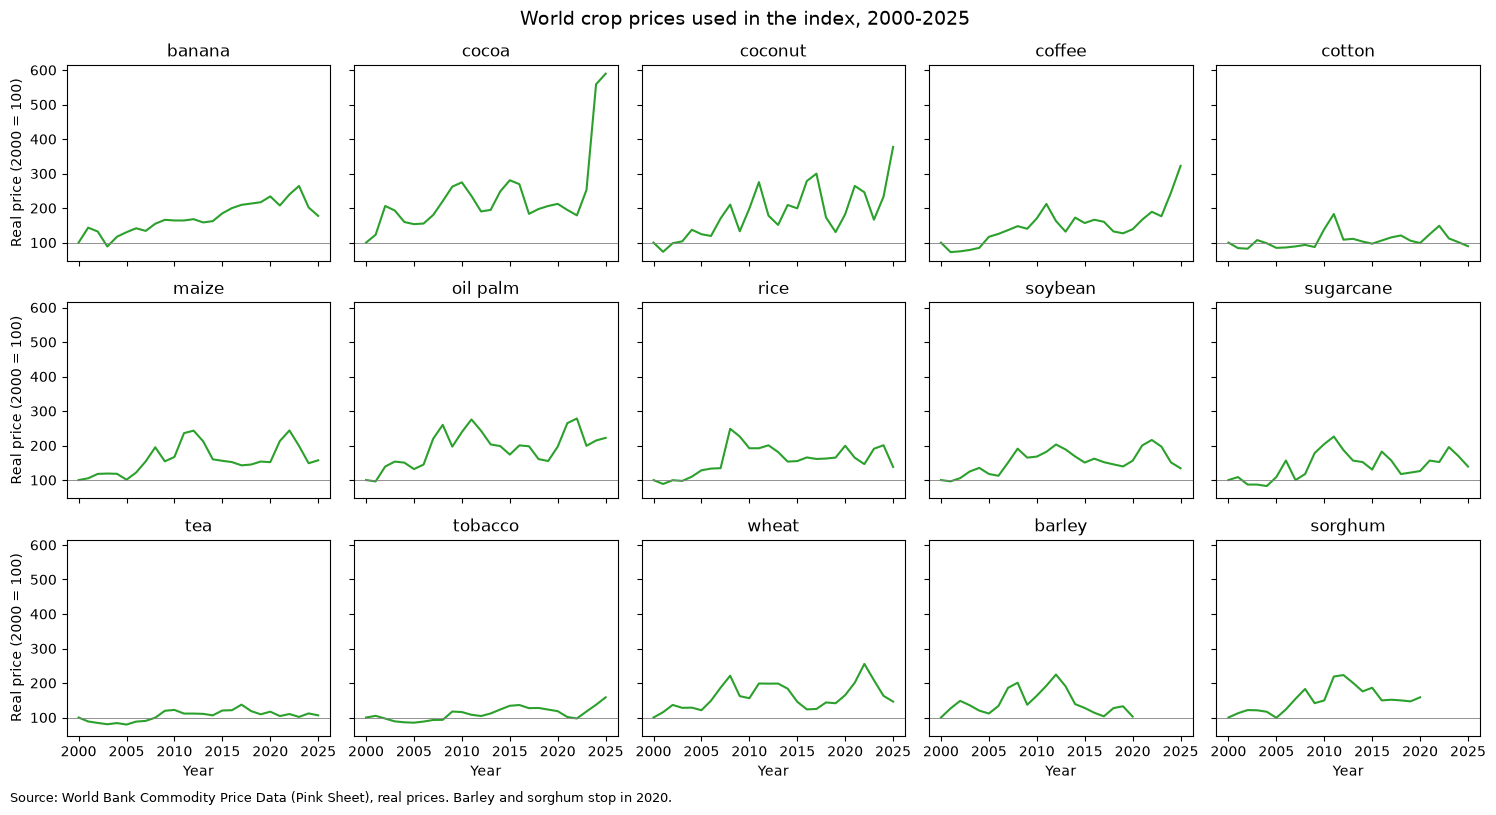

In [7]:
fig, axes = plt.subplots(3, 5, figsize=(15, 8), sharex=True, sharey=True)
for ax, crop in zip(axes.flat, CROPS_15):
    ax.plot(P.index, P[crop], color="tab:green")
    ax.axhline(100, color="grey", lw=0.6)
    ax.set_title(crop)
for ax in axes[:, 0]:
    ax.set_ylabel("Real price (2000 = 100)")
for ax in axes[-1]:
    ax.set_xlabel("Year")
fig.suptitle("World crop prices used in the index, 2000-2025", fontsize=14)
fig.text(0.01, -0.01, SOURCE_PRICE + " Barley and sorghum stop in 2020.", fontsize=9)
fig.tight_layout()
fig.savefig("../figures/crop_prices.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
# Correlation of log prices across crops, 2001-2025 (Berman et al., Table OA.2)
corr = np.log(P.loc[2001:2025, CROPS_13]).corr()
print(f"pairwise correlations: min {corr.values[np.triu_indices(13, 1)].min():.2f}, "
      f"median {np.median(corr.values[np.triu_indices(13, 1)]):.2f}, max {corr.values[np.triu_indices(13, 1)].max():.2f}")
corr.round(2)

pairwise correlations: min -0.09, median 0.57, max 0.92


,banana,cocoa,coconut,coffee,cotton,maize,oil palm,rice,soybean,sugarcane,tea,tobacco,wheat
banana,1.00,0.31,0.54,0.60,0.37,0.51,0.42,0.58,0.53,0.56,0.73,0.61,0.38
cocoa,0.31,1.00,0.59,0.74,0.05,0.21,0.42,0.40,0.20,0.37,0.41,0.73,0.11
coconut,0.54,0.59,1.00,0.88,0.50,0.58,0.79,0.53,0.62,0.54,0.65,0.55,0.38
coffee,0.60,0.74,0.88,1.00,0.40,0.61,0.75,0.63,0.59,0.71,0.61,0.63,0.47
cotton,0.37,0.05,0.50,0.40,1.00,0.67,0.61,0.34,0.63,0.55,0.46,0.11,0.46
maize,0.51,0.21,0.58,0.61,0.67,1.00,0.87,0.67,0.92,0.65,0.52,0.18,0.87
oil palm,0.42,0.42,0.79,0.75,0.61,0.87,1.00,0.71,0.88,0.60,0.53,0.21,0.78
rice,0.58,0.40,0.53,0.63,0.34,0.67,0.71,1.00,0.75,0.69,0.69,0.37,0.57
soybean,0.53,0.20,0.62,0.59,0.63,0.92,0.88,0.75,1.00,0.62,0.56,0.17,0.83
sugarcane,0.56,0.37,0.54,0.71,0.55,0.65,0.60,0.69,0.62,1.00,0.67,0.45,0.44


## 5. Relative suitability and price index

Berman et al. (2023), equations (1) and (2):
`alpha[i,c] = S[i,c] / sum_j S[j,c]` and `Price[c,t] = sum_i alpha[i,c] * P[i,t]`.

In [9]:
def price_index(crops, years):
    """Log price index (cells x years) and the relative suitability weights."""
    S = suit[crops].to_numpy()
    ok = S.sum(axis=1) > 0
    alpha = np.full_like(S, np.nan)
    alpha[ok] = S[ok] / S[ok].sum(axis=1, keepdims=True)
    index = alpha @ P.loc[years, crops].to_numpy().T          # cells x years
    return pd.DataFrame(np.log(index), index=cells.cell_id, columns=years), pd.DataFrame(alpha, columns=crops)

lnP13, alpha13 = price_index(CROPS_13, YEARS_13)
lnP15, alpha15 = price_index(CROPS_15, YEARS_15)
print("13 crops:", lnP13.shape, "| 15 crops:", lnP15.shape)
lnP13.describe().T[["mean", "std", "min", "max"]].iloc[::4].round(3)

13 crops: (511427, 25) | 15 crops: (511427, 18)


,mean,std,min,max
2001,4.606,0.039,4.433,4.749
2005,4.718,0.076,4.378,4.860
2009,5.077,0.091,4.468,5.252
2013,5.099,0.063,4.706,5.358
2017,5.051,0.129,4.747,5.316
2021,5.170,0.095,4.620,5.440
2025,5.223,0.262,4.496,5.700


In [10]:
# Mean weight of each crop over forest cells: which crops drive the index?
w = cells.forest25_ha / cells.forest25_ha.sum()
pd.DataFrame({
    "mean alpha (cells)": alpha13.mean(),
    "mean alpha (forest weighted)": alpha13.mul(w.values, axis=0).sum() / w[alpha13.notna().all(axis=1).values].sum(),
}).sort_values("mean alpha (forest weighted)", ascending=False).round(3)

,mean alpha (cells),mean alpha (forest weighted)
rice,0.107,0.112
soybean,0.115,0.097
coffee,0.068,0.091
sugarcane,0.069,0.087
banana,0.061,0.085
cocoa,0.059,0.083
maize,0.109,0.082
tea,0.053,0.075
tobacco,0.094,0.064
coconut,0.046,0.063


## 6. Maps

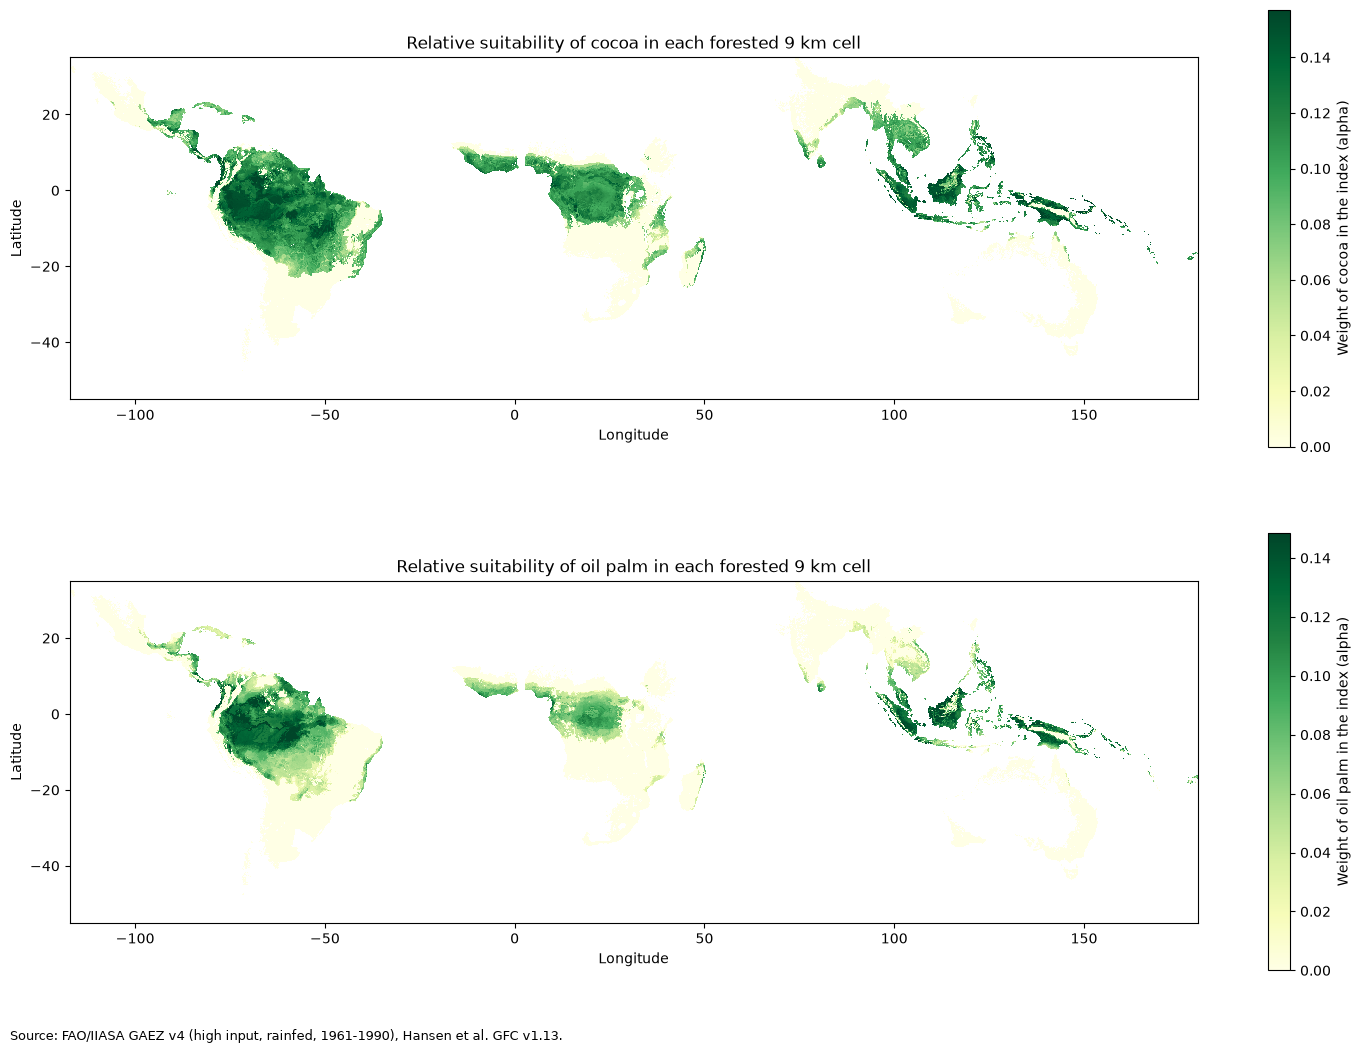

In [11]:
def to_grid(values):
    """Put one value per cell back on the 2160 x 4320 GAEZ grid, cropped to the sample."""
    g = np.full((2160, 4320), np.nan)
    g[cells.row.values, cells.col.values] = values
    r0, r1 = cells.row.min(), cells.row.max() + 1
    c0, c1 = cells.col.min(), cells.col.max() + 1
    extent = [-180 + c0 / 12, -180 + c1 / 12, 90 - r1 / 12, 90 - r0 / 12]
    return g[r0:r1, c0:c1], extent

# Weight of two crops in the index of each cell. In humid forests many crops are suitable, so weights
# are close to each other: a map of the "dominant" crop would exaggerate small differences.
fig, axes = plt.subplots(2, 1, figsize=(15, 11))
for ax, crop in zip(axes, ["cocoa", "oil palm"]):
    g, extent = to_grid(alpha13[crop].values)
    im = ax.imshow(g, extent=extent, cmap="YlGn", vmin=0, vmax=np.nanpercentile(alpha13[crop], 99),
                   interpolation="nearest")
    fig.colorbar(im, ax=ax, shrink=0.8, label=f"Weight of {crop} in the index (alpha)")
    ax.set_title(f"Relative suitability of {crop} in each forested 9 km cell")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
fig.text(0.01, 0.0, SOURCE_GAEZ, fontsize=9)
fig.tight_layout()
fig.savefig("../figures/crop_weight_maps.png", dpi=200, bbox_inches="tight")
plt.show()

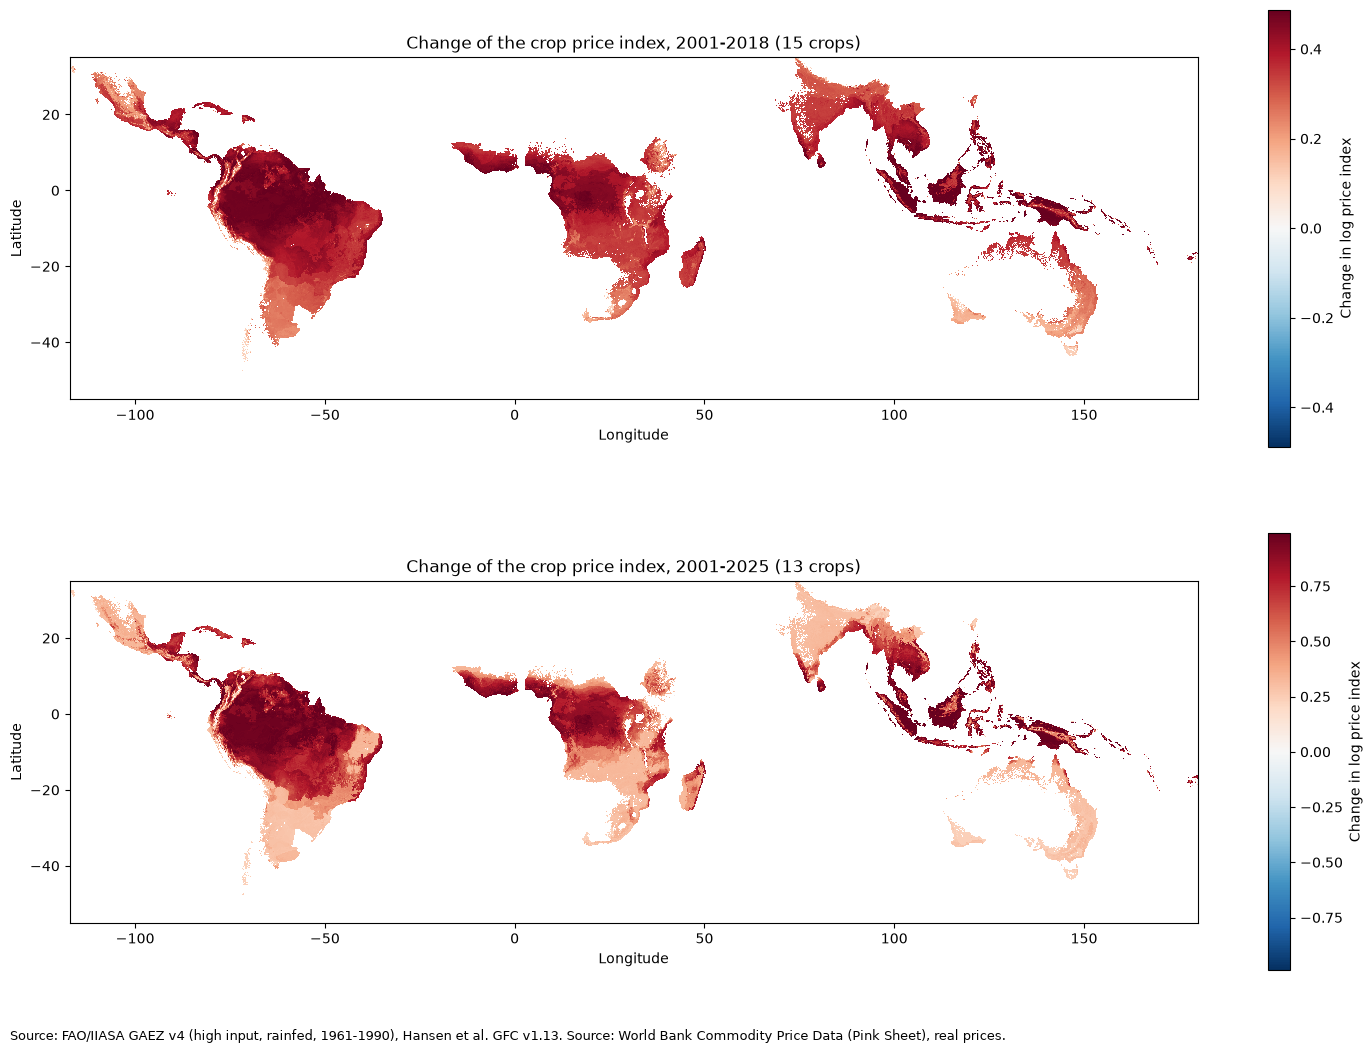

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(15, 11))
for ax, (lnP, y1, n) in zip(axes, [(lnP15, 2018, 15), (lnP13, 2025, 13)]):
    change = (lnP[y1] - lnP[2001]).values
    g, extent = to_grid(change)
    lim = np.nanpercentile(np.abs(change), 98)
    im = ax.imshow(g, extent=extent, cmap="RdBu_r", vmin=-lim, vmax=lim, interpolation="nearest")
    fig.colorbar(im, ax=ax, shrink=0.8, label="Change in log price index")
    ax.set_title(f"Change of the crop price index, 2001-{y1} ({n} crops)")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
fig.text(0.01, 0.0, SOURCE_GAEZ + " " + SOURCE_PRICE, fontsize=9)
fig.tight_layout()
fig.savefig("../figures/price_index_change_map.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Identifying variation

The regression uses cell fixed effects and country x year fixed effects. What is left of the price index
after removing them is the variation that identifies beta.

In [13]:
def residual_sd(lnP, n_iter=30):
    """SD of the log index raw, after cell FE, and after cell + country x year FE (alternating projections)."""
    long = lnP.reset_index().melt(id_vars="cell_id", var_name="year", value_name="y").dropna()
    long["iso3"] = long.cell_id.map(cells.set_index("cell_id").iso3)
    long["ct"] = long.iso3 + "_" + long.year.astype(str)
    y = long.y.to_numpy(np.float64).copy()
    out = {"raw": y.std()}
    y -= long.groupby("cell_id").y.transform("mean").to_numpy()
    out["after cell FE"] = y.std()
    for _ in range(n_iter):
        y -= pd.Series(y).groupby(long.ct.values).transform("mean").to_numpy()
        y -= pd.Series(y).groupby(long.cell_id.values).transform("mean").to_numpy()
    out["after cell + country x year FE"] = y.std()
    return pd.Series(out)

pd.DataFrame({"13 crops, 2001-2025": residual_sd(lnP13), "15 crops, 2001-2018": residual_sd(lnP15)}).round(4)

,"13 crops, 2001-2025","15 crops, 2001-2018"
raw,0.2217,0.2126
after cell FE,0.2047,0.2032
after cell + country x year FE,0.0472,0.0381


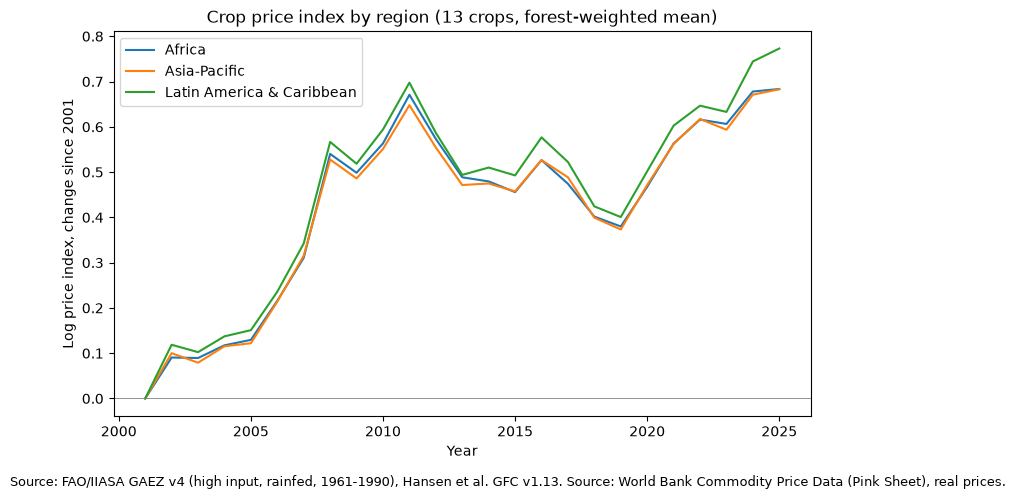

In [14]:
# Average log index by region (forest weighted), relative to 2001
fig, ax = plt.subplots(figsize=(9, 5))
for region, grp in cells.groupby("region"):
    m = lnP13.loc[grp.cell_id].mul(grp.forest25_ha.values, axis=0).sum() / grp.forest25_ha.sum()
    ax.plot(m.index, m - m.loc[2001], label=region)
ax.axhline(0, color="grey", lw=0.6)
ax.set_xlabel("Year")
ax.set_ylabel("Log price index, change since 2001")
ax.set_title("Crop price index by region (13 crops, forest-weighted mean)")
ax.legend()
fig.text(0.01, -0.03, SOURCE_GAEZ + " " + SOURCE_PRICE, fontsize=9)
fig.savefig("../figures/price_index_by_region.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Save the suitability of each cell

The regression notebook rebuilds the index from this file (suitability index 0-10,000, 15 crops),
so both versions of the index (13 and 15 crops) come from the same numbers.

In [15]:
out = suit.copy()
out[CROPS_15] = (out[CROPS_15] * 10000).round().astype("int16")
out.columns = ["cell_id"] + [f"suit_{c.replace(' ', '_')}" for c in CROPS_15]
out.to_csv("../data/processed/grid_suitability.csv.gz", index=False, compression="gzip")
print(out.shape)
out.head()

(511427, 16)


,cell_id,suit_banana,suit_cocoa,suit_coconut,suit_coffee,suit_cotton,suit_maize,suit_oil_palm,suit_rice,suit_soybean,suit_sugarcane,suit_tea,suit_tobacco,suit_wheat,suit_barley,suit_sorghum
0,4667871,3606,3606,4600,3606,1248,1828,2424,4005,4653,3495,3214,1173,0,0,0
1,4667872,3335,3368,4291,3368,1155,1997,2180,3930,4471,3227,3973,1248,0,0,0
2,4667873,5169,5808,7047,5808,1854,2975,3905,5950,4665,5136,4174,1694,0,0,0
3,4667874,5485,6344,7522,6344,1958,3286,4294,6358,4554,5472,4345,2411,0,0,0
4,4667875,6363,6590,7918,6590,1921,3481,4966,6594,5309,6350,4680,2863,0,0,0
